In [1]:
import warnings 
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Source of the data: https://archive.ics.uci.edu/dataset/863/maternal+health+risk
Age
Systolic Blood Pressure as SystolicBP
Diastolic BP as DiastolicBP
Blood Sugar as BS
Body Temperature as BodyTemp
HeartRate 
RiskLevel

In [3]:
#Reading the data
df = pd.read_csv("Maternal Health Risk Data Set.csv")

In [4]:
#Checking the first 10 features
df.head(10)

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.00,98.0,86,high risk
1,35,140,90,13.00,98.0,70,high risk
2,29,90,70,8.00,100.0,80,high risk
3,30,140,85,7.00,98.0,70,high risk
4,35,120,60,6.10,98.0,76,low risk
5,23,140,80,7.01,98.0,70,high risk
6,23,130,70,7.01,98.0,78,mid risk
7,35,85,60,11.00,102.0,86,high risk
8,32,120,90,6.90,98.0,70,mid risk
9,42,130,80,18.00,98.0,70,high risk


In [5]:
#Checking the shape of the data
df.shape

(1014, 7)

In [6]:
#Checking some information about the data
df.describe()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,29.871795,113.198225,76.460552,8.725986,98.665089,74.301775
std,13.474386,18.403913,13.885796,3.293532,1.371384,8.088702
min,10.000000,70.000000,49.000000,6.000000,98.000000,7.000000
25%,19.000000,100.000000,65.000000,6.900000,98.000000,70.000000
50%,26.000000,120.000000,80.000000,7.500000,98.000000,76.000000
75%,39.000000,120.000000,90.000000,8.000000,98.000000,80.000000
max,70.000000,160.000000,100.000000,19.000000,103.000000,90.000000


In [7]:
#Checking information regarding type (Risk level need to be encoded
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


In [8]:
#Checking if there is missing values
df.isnull().sum()

Age            0
SystolicBP     0
DiastolicBP    0
BS             0
BodyTemp       0
HeartRate      0
RiskLevel      0
dtype: int64

In [9]:
print(df[df.duplicated()])

      Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate  RiskLevel
67     19         120           80   7.0      98.0         70   mid risk
72     19         120           80   7.0      98.0         70   mid risk
97     19         120           80   7.0      98.0         70   mid risk
106    50         140           90  15.0      98.0         90  high risk
107    25         140          100   6.8      98.0         80  high risk
...   ...         ...          ...   ...       ...        ...        ...
1009   22         120           60  15.0      98.0         80  high risk
1010   55         120           90  18.0      98.0         60  high risk
1011   35          85           60  19.0      98.0         86  high risk
1012   43         120           90  18.0      98.0         70  high risk
1013   32         120           65   6.0     101.0         76   mid risk

[562 rows x 7 columns]


# Using unique, count values and histogram to take a look at the data

In [10]:
df['RiskLevel'].unique()

array(['high risk', 'low risk', 'mid risk'], dtype=object)

In [11]:
df['RiskLevel'].value_counts()

RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64

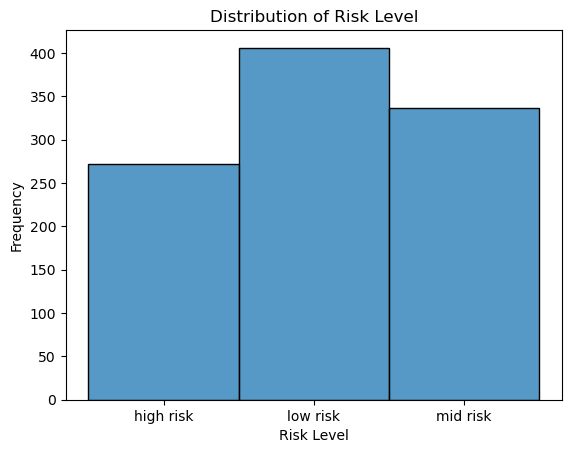

In [12]:
#Graphs of Risk Level
data=df['RiskLevel']

sns.histplot(data=data, bins=10)

plt.title('Distribution of Risk Level')
plt.xlabel('Risk Level')
plt.ylabel('Frequency')
plt.show()

In [13]:
df['Age'].unique()

array([25, 35, 29, 30, 23, 32, 42, 19, 20, 48, 15, 50, 10, 40, 21, 18, 16,
       22, 49, 28, 12, 60, 55, 45, 31, 17, 26, 54, 44, 33, 13, 34, 38, 39,
       63, 14, 37, 51, 62, 43, 65, 66, 56, 70, 27, 36, 59, 24, 41, 46],
      dtype=int64)

In [14]:
df['Age'].value_counts()

Age
23    71
19    67
17    63
15    60
35    50
25    48
32    48
22    45
50    43
29    40
21    38
40    37
55    37
12    35
60    34
30    30
28    28
48    26
42    23
20    22
31    22
18    19
16    16
54    12
13    12
27     9
49     9
45     9
37     6
33     5
34     5
43     5
10     4
36     4
39     4
24     3
65     3
44     3
14     3
26     3
63     2
38     2
59     2
62     1
51     1
66     1
56     1
70     1
41     1
46     1
Name: count, dtype: int64

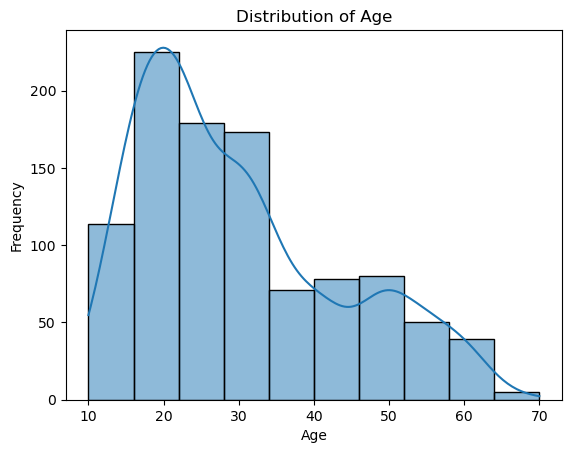

In [15]:
#Graphs of Age
data=df['Age']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

In [16]:
df['SystolicBP'].unique()

array([130, 140,  90, 120,  85, 110,  70, 100,  75,  95,  76,  80, 115,
       135, 160, 129,  83,  99,  78], dtype=int64)

In [17]:
df['SystolicBP'].value_counts()

SystolicBP
120    449
90     154
140    120
100     92
130     60
85      43
110     19
76      16
95      12
160     10
75       8
115      8
70       7
80       5
135      3
78       3
83       2
99       2
129      1
Name: count, dtype: int64

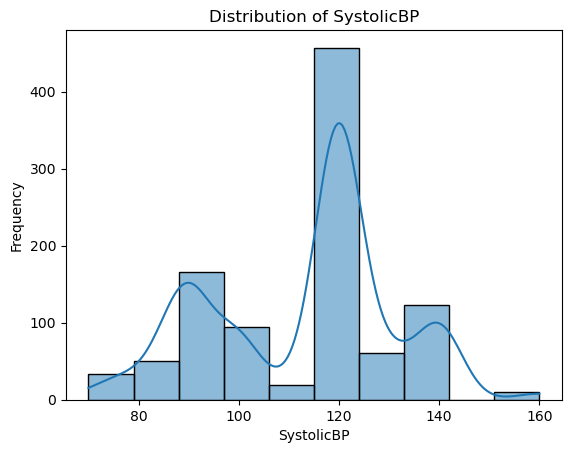

In [18]:
#Graphs of SystolicBP
data=df['SystolicBP']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of SystolicBP')
plt.xlabel('SystolicBP')
plt.ylabel('Frequency')
plt.show()

In [19]:
df['DiastolicBP'].unique()

array([ 80,  90,  70,  85,  60,  89,  75, 100,  50,  65,  95,  49,  63,
        69,  76,  68], dtype=int64)

In [20]:
df['DiastolicBP'].value_counts()

DiastolicBP
80     226
60     174
90     153
70     100
100     87
65      87
85      49
75      38
95      36
49      25
50      24
63       8
76       3
68       2
89       1
69       1
Name: count, dtype: int64

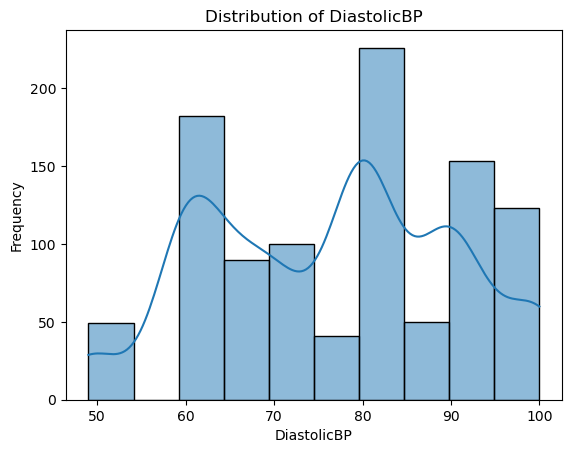

In [21]:
#Graphs of DiastolicBP
data=df['DiastolicBP']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of DiastolicBP')
plt.xlabel('DiastolicBP')
plt.ylabel('Frequency')
plt.show()

In [22]:
df['BS'].unique()

array([15.  , 13.  ,  8.  ,  7.  ,  6.1 ,  7.01, 11.  ,  6.9 , 18.  ,
        6.7 ,  7.5 ,  7.2 ,  7.1 ,  6.4 ,  9.  ,  6.  ,  7.7 , 12.  ,
       16.  ,  7.8 ,  6.8 ,  7.9 , 17.  , 19.  , 10.  ,  6.3 ,  6.6 ,
        6.5 ,  7.6 ])

In [23]:
df['BS'].value_counts()

BS
7.50     176
6.90     113
6.80      88
7.00      79
7.90      60
15.00     54
6.10      53
11.00     52
7.80      45
6.70      33
9.00      31
18.00     29
7.70      24
19.00     22
8.00      22
6.00      21
7.20      20
12.00     18
16.00     17
7.01      15
6.40      10
13.00      9
7.10       8
17.00      5
10.00      4
6.30       2
6.60       2
6.50       1
7.60       1
Name: count, dtype: int64

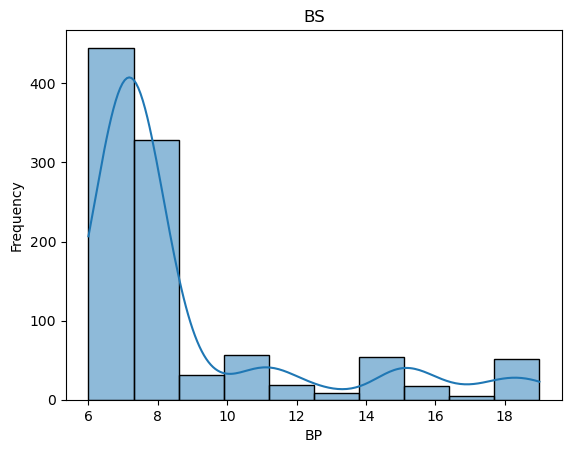

In [24]:
#Graphs of BS
data=df['BS']

sns.histplot(data=data, bins=10, kde=True)

plt.title('BS')
plt.xlabel('BP')
plt.ylabel('Frequency')
plt.show()

In [25]:
df['BodyTemp'].unique()

array([ 98. , 100. , 102. , 101. , 103. ,  98.4,  99. ,  98.6])

In [26]:
df['BodyTemp'].value_counts()

BodyTemp
98.0     804
101.0     98
102.0     66
100.0     20
103.0     13
99.0      10
98.4       2
98.6       1
Name: count, dtype: int64

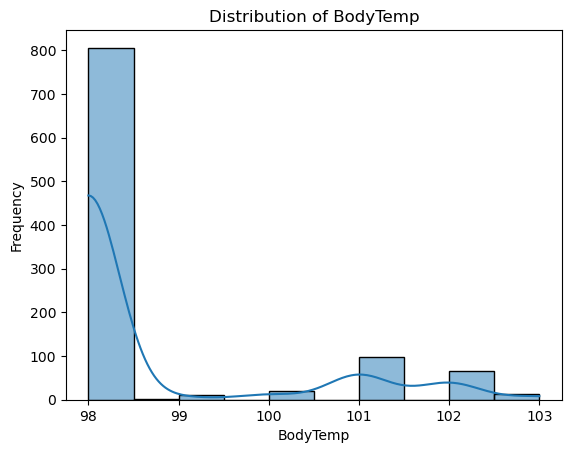

In [27]:
#Graphs of BodyTemp
data=df['BodyTemp']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of BodyTemp')
plt.xlabel('BodyTemp')
plt.ylabel('Frequency')
plt.show()

In [28]:
df['HeartRate'].unique()

array([86, 70, 80, 76, 78, 77, 88, 90, 66, 82, 60, 75, 67, 65, 68,  7],
      dtype=int64)

In [29]:
df['HeartRate'].value_counts()

HeartRate
70    271
76    131
80    117
77     96
66     87
60     74
88     59
86     55
78     46
90     19
82     19
75     19
67     12
65      5
68      2
7       2
Name: count, dtype: int64

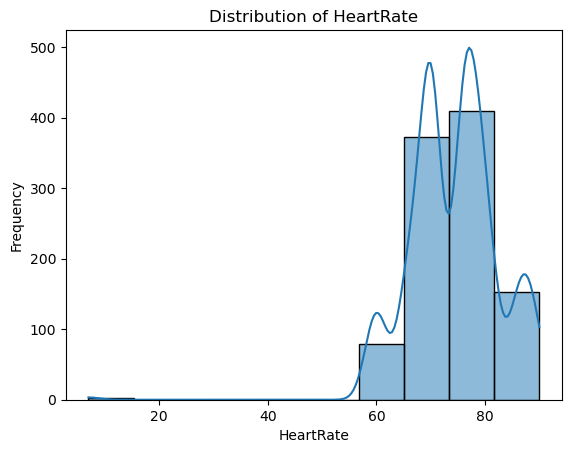

In [30]:
#Graphs of HeartRate
data=df['HeartRate']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of HeartRate')
plt.xlabel('HeartRate')
plt.ylabel('Frequency')
plt.show()

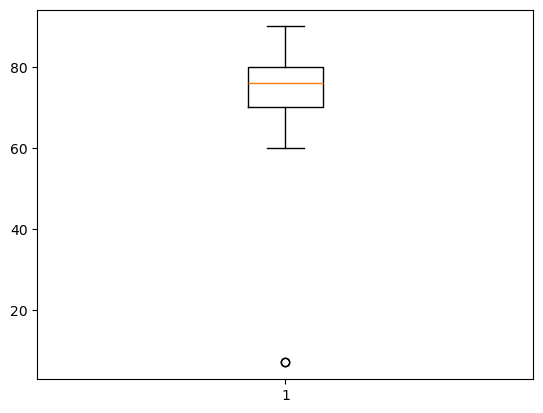

In [31]:
# Checking outliers of Heart Rate using boxplot. We need to remove the 2 data with heart rate = 7
plt.boxplot(df['HeartRate'])

plt.show()

In [32]:
#Drop the Outliers from Heart Rate
df = df[df["HeartRate"] != 7]

In [33]:
df.shape

(1012, 7)

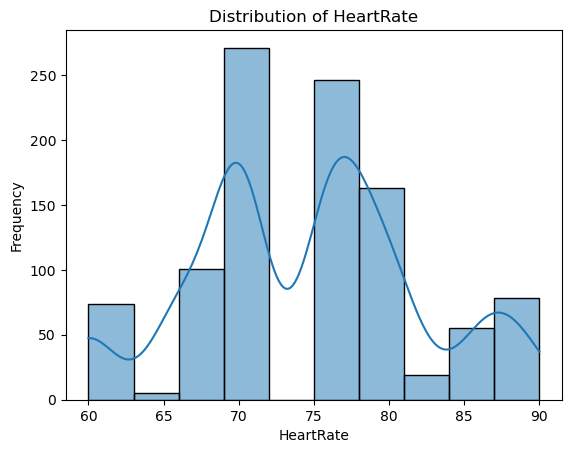

In [34]:
#Graphs of HeartRate
data=df['HeartRate']

sns.histplot(data=data, bins=10, kde=True)

plt.title('Distribution of HeartRate')
plt.xlabel('HeartRate')
plt.ylabel('Frequency')
plt.show()

In [35]:
# Replace categorical data "low risk", "mid risk" and "high risk" with 0, 1 and 2 - according to the Tutorial 2 - Machine Learning module
df['RiskLevel'].replace('low risk', 0, inplace = True)
df['RiskLevel'].replace('mid risk', 1, inplace = True)
df['RiskLevel'].replace('high risk', 2, inplace = True)

In [36]:
print(df['RiskLevel'].value_counts())

RiskLevel
0    404
1    336
2    272
Name: count, dtype: int64


# Machine Learning

In [37]:
# Splitting X and y
label = df[['RiskLevel']]

In [38]:
label.head()

,RiskLevel
0,2
1,2
2,2
3,2
4,0


In [39]:
# Drop the label column (Last)
df_new = df.drop(['RiskLevel'], axis = 1)

In [40]:
df_new.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate
0,25,130,80,15.0,98.0,86
1,35,140,90,13.0,98.0,70
2,29,90,70,8.0,100.0,80
3,30,140,85,7.0,98.0,70
4,35,120,60,6.1,98.0,76


In [41]:
#Loading the libraries 

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [42]:
#Defining X and y
X = df_new
y = label

print(X, '\n', y)

      Age  SystolicBP  DiastolicBP    BS  BodyTemp  HeartRate
0      25         130           80  15.0      98.0         86
1      35         140           90  13.0      98.0         70
2      29          90           70   8.0     100.0         80
3      30         140           85   7.0      98.0         70
4      35         120           60   6.1      98.0         76
...   ...         ...          ...   ...       ...        ...
1009   22         120           60  15.0      98.0         80
1010   55         120           90  18.0      98.0         60
1011   35          85           60  19.0      98.0         86
1012   43         120           90  18.0      98.0         70
1013   32         120           65   6.0     101.0         76

[1012 rows x 6 columns] 
       RiskLevel
0             2
1             2
2             2
3             2
4             0
...         ...
1009          2
1010          2
1011          2
1012          2
1013          1

[1012 rows x 1 columns]


In [49]:
# Show count of each class in the target variable
class_counts = y.value_counts()
print("Count of each class in 'Risk Level' (Risk Level):")
print(class_counts)

Count of each class in 'Risk Level' (Risk Level):
RiskLevel
0            404
1            336
2            272
Name: count, dtype: int64


In [65]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.15, random_state = 42)

In [66]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

In [67]:
# Train and evaluate ML model classifiers
results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [68]:
# Convert results to DataFrame for easy viewing
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on Test Set:")
print(results_df)

Model Performance Metrics on Test Set:
                    Model  Accuracy  Precision    Recall  F1 Score
0     k-Nearest Neighbors  0.677632   0.679036  0.677632  0.678208
1           Decision Tree  0.822368   0.822742  0.822368  0.822156
2           Random Forest  0.822368   0.825833  0.822368  0.822193
3     Logistic Regression  0.598684   0.579318  0.598684  0.575259
4  Support Vector Machine  0.611842   0.597589  0.611842  0.582900


In [69]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                    Model  Mean CV Accuracy
0     k-Nearest Neighbors          0.668605
1           Decision Tree          0.831395
2           Random Forest          0.845349
3     Logistic Regression          0.632558
4  Support Vector Machine          0.654651


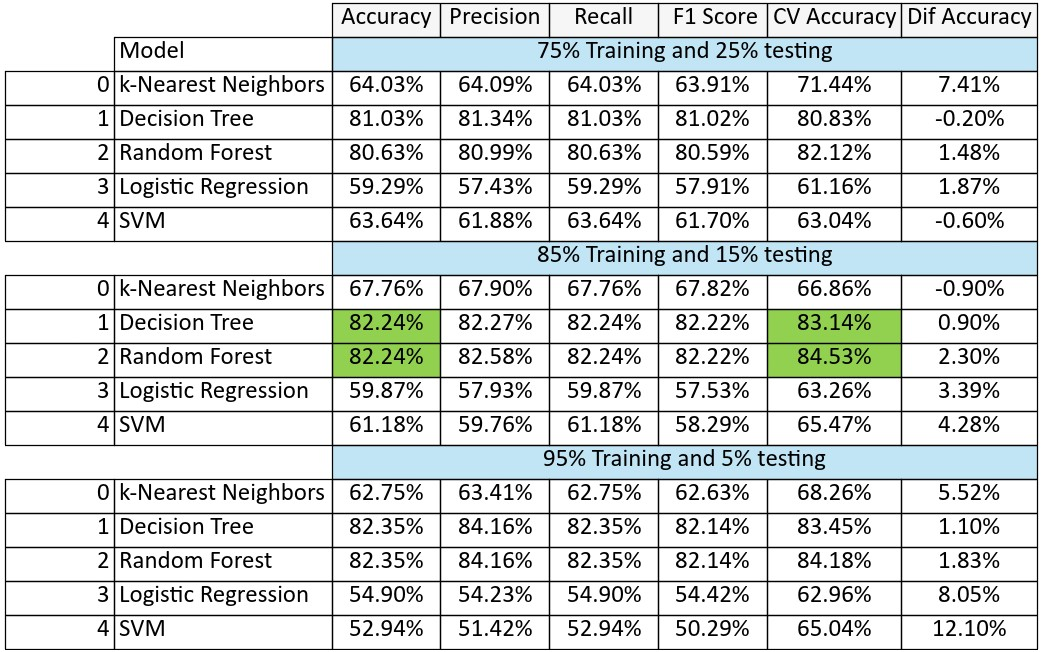

In [71]:
# Results for 5%, 15% and 25% for testing. Decision Tree and Randon Forest with 15% more reliable. More insight about the data at the support document
from IPython.display import Image
Image(filename =r'Accuracy_train_test.jpg')